In [14]:
import pandas as pd
file_path = r"C:\Users\HP\OneDrive\Documents\cleaned_menu.csv.xlsx"

df = pd.read_excel(file_path)

print("First 5 rows:")
print(df.head())

print("\nActual columns names:")
print(df.columns.tolist())

print("\nRows and columns:")
print(df.shape)

print("\nData types:")
print(df.dtypes)


First 5 rows:
                           item_id           item_name   category  \
0   MCD_BEVE_Coca-Cola_(Small)_607   Coca-Cola (Small)  Beverages   
1  MCD_BEVE_Coca-Cola_(Medium)_972  Coca-Cola (Medium)  Beverages   
2   MCD_BEVE_Coca-Cola_(Large)_129   Coca-Cola (Large)  Beverages   
3   MCD_BEVE_Diet_Coke_(Small)_570   Diet Coke (Small)  Beverages   
4      MCD_BEVE_Sprite_(Small)_816      Sprite (Small)  Beverages   

                             description  price_usd  calories  \
0         Freshly made coca-cola (small)       1.63       157   
1  Classic McDonald's coca-cola (medium)       3.22       220   
2   Classic McDonald's coca-cola (large)       2.99       315   
3   Classic McDonald's diet coke (small)       1.67         3   
4      Classic McDonald's sprite (small)       2.41       147   

   calories_from_fat  total_fat_g  saturated_fat_g  trans_fat_g  ...  \
0                 76            0              0.0          0.0  ...   
1                 88            0   

In [24]:
print("===== DATA CLEANING REPORT =====")

print("\n1. Dataset Shape:")
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])


print('\n2.Missing Values:')
print(df.isnull().sum())

print('Total Missing Values:')
print(df.isnull().sum().sum())

print('\n3.Duplicate Rows:')
print('Total Duplicates:',
     df.dupplicate().sum())

print('\n4.Columns Names:')
print(df.columns.tolist())

print('\n5.Data Types:')
print(df.dtypes)


print('\n6.Empty Text Values:')
text_cols = df.select_dtypes( 
    include=['object','string']
).columns

for col in col_text_cols:
    empty_counts=(
df[col].astype('string').str.strp().eq('').sum())
print(f'{col}:{empty_counts}')

        print('\n7.Negative Values in Numeric columns:')
numeric_cols= df.select_dtypes(
    include='number'
).columns

for colin numeric_cols:
print(f'{col}:{(df[col]<0).sum()}')

print('\n=====AUDIT COMPLETE=====')

IndentationError: unindent does not match any outer indentation level (<string>, line 33)

In [25]:

print("===== DATA CLEANING AUDIT =====")

# 1. Dataset size
print("\nDataset Shape:", df.shape)

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum())
print("Total Missing:", df.isnull().sum().sum())

# 3. Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Data types
print("\nData Types:")
print(df.dtypes)

# 5. Empty text values
print("\nEmpty Text Values:")
text_cols = df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    empty_count = df[col].astype("string").str.strip().eq("").sum()
    print(col, ":", empty_count)

# 6. Negative numeric values
print("\nNegative Values:")
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    print(col, ":", (df[col] < 0).sum())

print("\n===== AUDIT COMPLETED =====")


===== DATA CLEANING AUDIT =====

Dataset Shape: (80, 36)

Missing Values:
item_id               0
item_name             0
category              0
description           0
price_usd             0
calories              0
calories_from_fat     0
total_fat_g           0
saturated_fat_g       0
trans_fat_g           0
cholesterol_mg        0
sodium_mg             0
total_carbs_g         0
dietary_fiber_g       0
sugars_g              0
protein_g             0
calcium_mg            0
iron_mg               0
vitamin_a_iu          0
vitamin_c_mg          0
is_vegetarian         0
is_gluten_free        0
is_dairy_free         0
is_low_calorie        0
is_high_protein       0
is_high_fiber         0
has_sizes             0
is_popular            0
is_limited_time       0
is_nationwide         0
serving_size          0
prep_time_minutes     0
price_per_calorie     0
protein_per_dollar    0
calorie_density       0
price_history         0
dtype: int64
Total Missing: 0

Duplicate Rows: 0

Data Types:


In [26]:

# FINAL DATA QUALITY CHECKS

print("1. Total duplicate rows:")
print(df.duplicated().sum())

print("\n2. Duplicate item IDs:")
print(df["item_id"].duplicated().sum())

print("\n3. Empty text values:")
text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    count = df[col].astype("string").str.strip().eq("").sum()
    if count > 0:
        print(col, ":", count)

print("\n4. Negative values in numeric columns:")
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    count = (df[col] < 0).sum()
    if count > 0:
        print(col, ":", count)

print("\n5. Data types:")
print(df.dtypes)


1. Total duplicate rows:
0

2. Duplicate item IDs:
0

3. Empty text values:

4. Negative values in numeric columns:
saturated_fat_g : 3
trans_fat_g : 3
dietary_fiber_g : 1
sugars_g : 1

5. Data types:
item_id                   str
item_name                 str
category                  str
description               str
price_usd             float64
calories                int64
calories_from_fat       int64
total_fat_g             int64
saturated_fat_g       float64
trans_fat_g           float64
cholesterol_mg          int64
sodium_mg               int64
total_carbs_g           int64
dietary_fiber_g       float64
sugars_g              float64
protein_g               int64
calcium_mg              int64
iron_mg               float64
vitamin_a_iu            int64
vitamin_c_mg            int64
is_vegetarian            bool
is_gluten_free           bool
is_dairy_free            bool
is_low_calorie           bool
is_high_protein          bool
is_high_fiber            bool
has_sizes          

In [27]:

# Inspect negative values before changing anything

cols_to_check = [
    "saturated_fat_g",
    "trans_fat_g",
    "dietary_fiber_g",
    "sugars_g"
]

for col in cols_to_check:
    print(f"\n--- {col} ---")
    print(df.loc[df[col] < 0, ["item_id", "item_name", col]])



--- saturated_fat_g ---
                            item_id           item_name  saturated_fat_g
1   MCD_BEVE_Coca-Cola_(Medium)_972  Coca-Cola (Medium)             -0.5
8             MCD_BEVE_Iced_Tea_701            Iced Tea             -0.3
60   MCD_MCCA_Americano_(Small)_213   Americano (Small)             -0.3

--- trans_fat_g ---
                            item_id           item_name  trans_fat_g
1   MCD_BEVE_Coca-Cola_(Medium)_972  Coca-Cola (Medium)         -0.1
8             MCD_BEVE_Iced_Tea_701            Iced Tea         -0.1
60   MCD_MCCA_Americano_(Small)_213   Americano (Small)         -0.1

--- dietary_fiber_g ---
                          item_id          item_name  dietary_fiber_g
3  MCD_BEVE_Diet_Coke_(Small)_570  Diet Coke (Small)             -0.1

--- sugars_g ---
                          item_id          item_name  sugars_g
3  MCD_BEVE_Diet_Coke_(Small)_570  Diet Coke (Small)      -0.3


In [28]:

import numpy as np

# Keep a backup before making changes
df_audited = df.copy()

cols_to_check = [
    "saturated_fat_g",
    "trans_fat_g",
    "dietary_fiber_g",
    "sugars_g"
]

for col in cols_to_check:
    df.loc[df[col] < 0, col] = np.nan

print("Negative values remaining:")
print((df[cols_to_check] < 0).sum())

print("\nMissing values after correction:")
print(df[cols_to_check].isna().sum())


Negative values remaining:
saturated_fat_g    0
trans_fat_g        0
dietary_fiber_g    0
sugars_g           0
dtype: int64

Missing values after correction:
saturated_fat_g    3
trans_fat_g        3
dietary_fiber_g    1
sugars_g           1
dtype: int64


In [29]:

output_path = r"C:\Users\HP\OneDrive\Documents\mcdonalds_final_cleaned.csv"

df.to_csv(output_path, index=False)

print("Final cleaned dataset saved successfully!")
print("Dataset shape:", df.shape)


Final cleaned dataset saved successfully!
Dataset shape: (80, 36)


In [30]:

print("===== FINAL DATA QUALITY REPORT =====")

print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Item IDs:", df["item_id"].duplicated().sum())

print("\nNegative Values in Checked Columns:")
cols = [
    "saturated_fat_g",
    "trans_fat_g",
    "dietary_fiber_g",
    "sugars_g"
]
print((df[cols] < 0).sum())

print("\nMissing Values by Column:")
print(df[cols].isnull().sum())


===== FINAL DATA QUALITY REPORT =====
Dataset Shape: (80, 36)
Total Missing Values: 8
Duplicate Rows: 0
Duplicate Item IDs: 0

Negative Values in Checked Columns:
saturated_fat_g    0
trans_fat_g        0
dietary_fiber_g    0
sugars_g           0
dtype: int64

Missing Values by Column:
saturated_fat_g    3
trans_fat_g        3
dietary_fiber_g    1
sugars_g           1
dtype: int64


In [31]:
# EDA - Step 1: Descriptive Statistics

print("===== NUMERICAL DATA ANALYSIS =====")

numeric_df = df.select_dtypes(include="number")

print("\nSummary Statistics:")
print(numeric_df.describe().round(2))

print("\nAverage Price (USD):")
print(round(df["price_usd"].mean(), 2))

print("\nMinimum Price (USD):")
print(df["price_usd"].min())

print("\nMaximum Price (USD):")
print(df["price_usd"].max())

print("\nAverage Calories:")
print(round(df["calories"].mean(), 2))

print("\nMedian Calories:")
print(df["calories"].median())

===== NUMERICAL DATA ANALYSIS =====

Summary Statistics:
       price_usd  calories  calories_from_fat  total_fat_g  saturated_fat_g  \
count      80.00     80.00              80.00        80.00            77.00   
mean        4.08    312.51             111.52        13.81             5.81   
std         1.72    179.69              68.03        10.89             4.60   
min         1.19      3.00               0.00         0.00             0.00   
25%         2.62    162.25              63.00         5.00             2.30   
50%         3.98    295.00              99.50        11.00             5.10   
75%         5.32    454.00             158.25        22.25             8.50   
max         7.70    783.00             373.00        48.00            22.70   

       trans_fat_g  cholesterol_mg  sodium_mg  total_carbs_g  dietary_fiber_g  \
count        77.00           80.00      80.00          80.00            79.00   
mean          1.33           42.90     463.71          35.81         

In [32]:
# EDA Step 2: Category-wise Analysis

category_analysis = df.groupby("category").agg(
    total_items=("item_id", "count"),
    average_price=("price_usd", "mean"),
    average_calories=("calories", "mean"),
    maximum_calories=("calories", "max")
).round(2)

print("===== CATEGORY-WISE ANALYSIS =====")
print(category_analysis.sort_values(
    by="average_price",
    ascending=False
))

===== CATEGORY-WISE ANALYSIS =====
                      total_items  average_price  average_calories  \
category                                                             
Burgers                        10           5.88            481.00   
Salads                          5           5.76            151.80   
Happy Meal                      4           5.69            367.00   
Chicken & Sandwiches            7           5.52            413.71   
Breakfast                      10           5.14            446.70   
Snacks & Sides                  9           3.32            251.33   
Desserts                       11           2.98            427.73   
McCafÃ©                        12           2.93            168.42   
Beverages                      12           2.38            134.42   

                      maximum_calories  
category                                
Burgers                            783  
Salads                             270  
Happy Meal                    

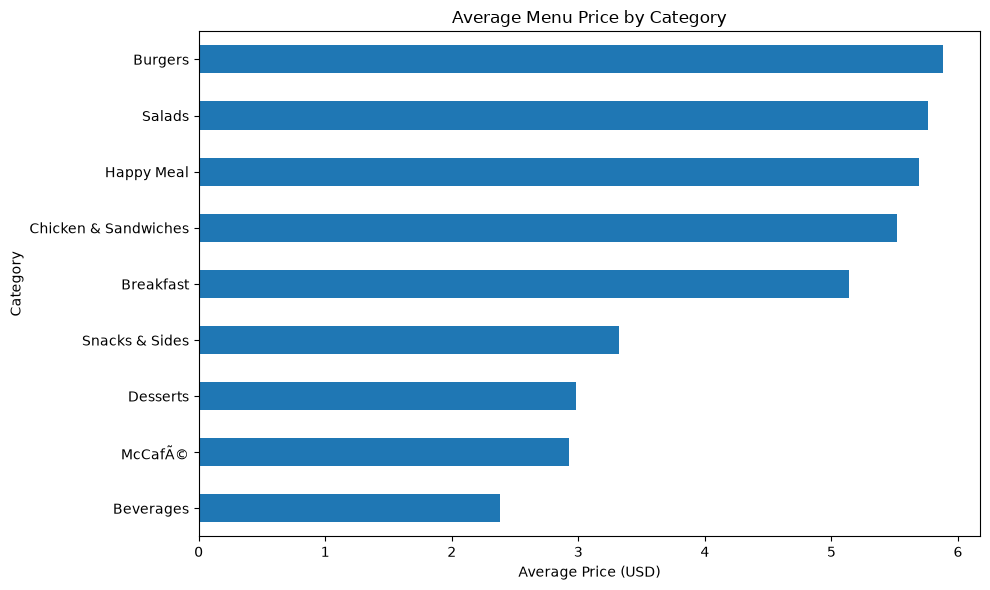

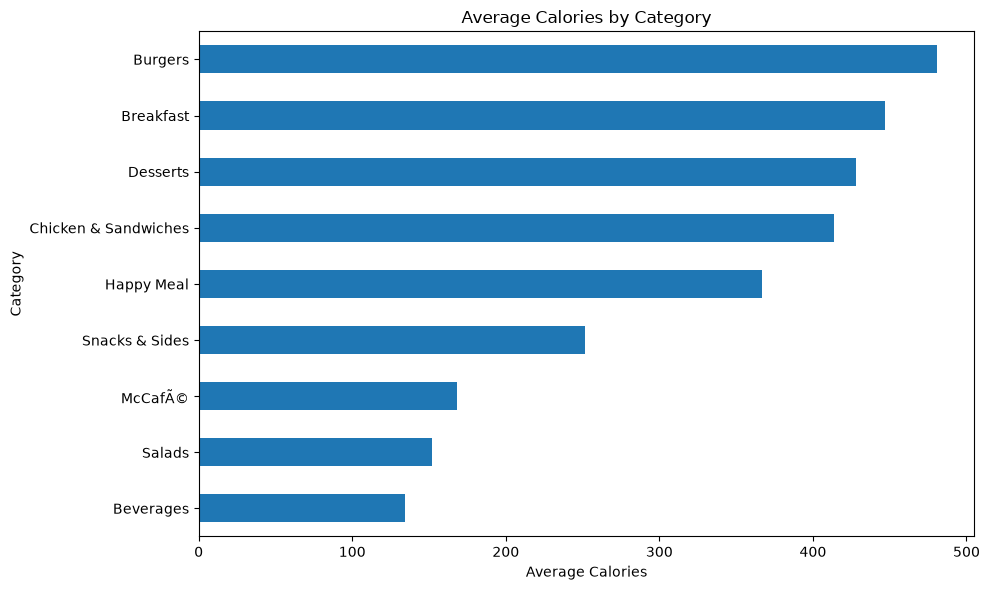

In [33]:
import matplotlib.pyplot as plt

# Graph 1: Average Price by Category
category_analysis["average_price"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Average Menu Price by Category"
)

plt.xlabel("Average Price (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


# Graph 2: Average Calories by Category
category_analysis["average_calories"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Average Calories by Category"
)

plt.xlabel("Average Calories")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

===== TOP 10 HIGHEST-CALORIE ITEMS =====
                         item_name  category  calories
Double Quarter Pounder with Cheese   Burgers       783
                  Deluxe Breakfast Breakfast       654
               McFlurry with M&M's  Desserts       639
                McFlurry with Oreo  Desserts       626
      McFlurry with Chocolate Chip  Desserts       608
Quarter Pounder with Cheese Deluxe   Burgers       577
                Big Mac with Bacon   Burgers       577
          Sausage Biscuit with Egg Breakfast       546
                           Big Mac   Burgers       530
           Chocolate Shake (Small)  Desserts       529


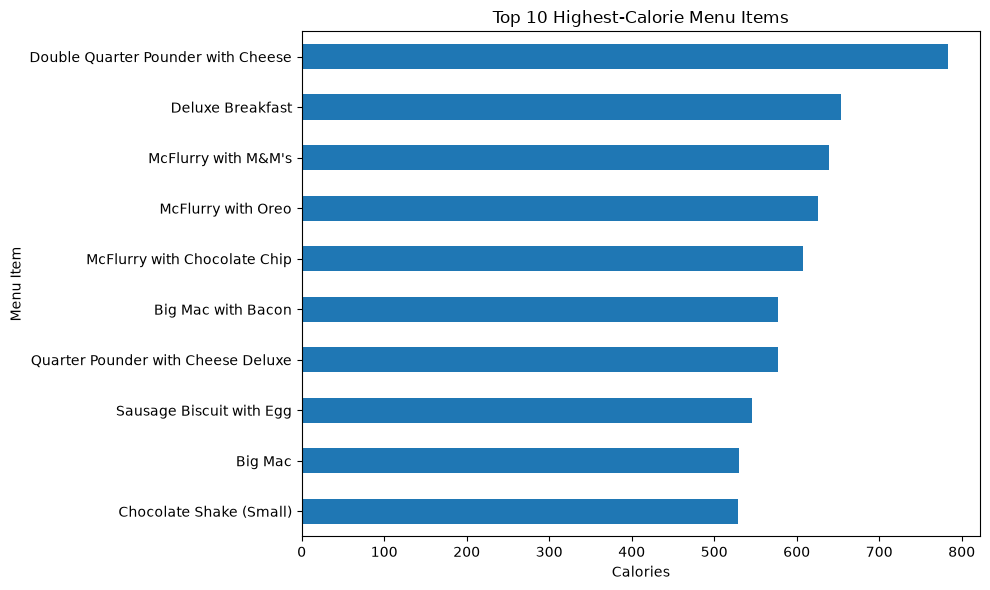


===== TOP 10 MOST EXPENSIVE ITEMS =====
                         item_name             category  price_usd
          Sausage Biscuit with Egg            Breakfast       7.70
                   Spicy McChicken Chicken & Sandwiches       7.26
   Southern Style Chicken Sandwich Chicken & Sandwiches       7.23
         Sausage McMuffin with Egg            Breakfast       7.10
       Quarter Pounder with Cheese              Burgers       7.03
                      Cheeseburger              Burgers       6.81
Quarter Pounder with Cheese Deluxe              Burgers       6.63
                           Big Mac              Burgers       6.55
                      Egg McMuffin            Breakfast       6.50
              Happy Meal Hamburger           Happy Meal       6.41


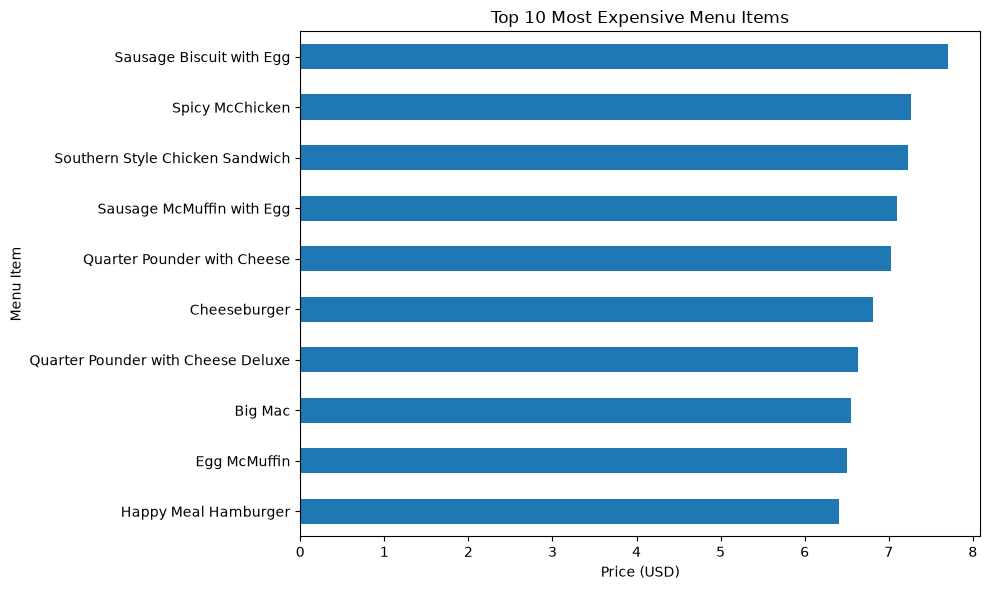

In [34]:
# EDA Step 4: Top 10 Items Analysis

import matplotlib.pyplot as plt

# Top 10 highest-calorie items
top_calories = df.nlargest(10, "calories")[
    ["item_name", "category", "calories"]
]

print("===== TOP 10 HIGHEST-CALORIE ITEMS =====")
print(top_calories.to_string(index=False))

top_calories.sort_values("calories").plot(
    x="item_name",
    y="calories",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    title="Top 10 Highest-Calorie Menu Items"
)

plt.xlabel("Calories")
plt.ylabel("Menu Item")
plt.tight_layout()
plt.show()


# Top 10 most expensive items
top_prices = df.nlargest(10, "price_usd")[
    ["item_name", "category", "price_usd"]
]

print("\n===== TOP 10 MOST EXPENSIVE ITEMS =====")
print(top_prices.to_string(index=False))

top_prices.sort_values("price_usd").plot(
    x="item_name",
    y="price_usd",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    title="Top 10 Most Expensive Menu Items"
)

plt.xlabel("Price (USD)")
plt.ylabel("Menu Item")
plt.tight_layout()
plt.show()

In [36]:
# EDA Step 5: Automated Business Insights

print("===== BUSINESS INSIGHTS =====")

print("\n1. Most expensive item:")
print(
    df.loc[df["price_usd"].idxmax(),
           ["item_name", "category", "price_usd"]]
)

print("\n2. Highest-calorie item:")
print(
    df.loc[df["calories"].idxmax(),
           ["item_name", "category", "calories"]]
)

print("\n3. Lowest-calorie item:")
print(
    df.loc[df["calories"].idxmin(),
           ["item_name", "category", "calories"]]
)

print("\n4. Highest average-price category:")
print(category_analysis["average_price"].idxmax())

print("\n5. Lowest average-calorie category:")
print(category_analysis["average_calories"].idxmin())

===== BUSINESS INSIGHTS =====

1. Most expensive item:
item_name    Sausage Biscuit with Egg
category                    Breakfast
price_usd                         7.7
Name: 17, dtype: object

2. Highest-calorie item:
item_name    Double Quarter Pounder with Cheese
category                                Burgers
calories                                    783
Name: 31, dtype: object

3. Lowest-calorie item:
item_name    Diet Coke (Small)
category             Beverages
calories                     3
Name: 3, dtype: object

4. Highest average-price category:
Burgers

5. Lowest average-calorie category:
Beverages


In [37]:
# Final Project Summary

print("=" * 45)
print("McDonald's Menu Data Analysis")
print("=" * 45)

print(f"Total Menu Items: {len(df)}")
print(f"Total Columns: {df.shape[1]}")
print(f"Menu Categories: {df['category'].nunique()}")
print(f"Average Price: ${df['price_usd'].mean():.2f}")
print(f"Average Calories: {df['calories'].mean():.2f}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Missing Values: {df.isnull().sum().sum()}")

print("\nProject Steps Completed:")
print("1. Data Cleaning")
print("2. Data Quality Audit")
print("3. Descriptive Statistics")
print("4. Category-wise Analysis")
print("5. Data Visualization")
print("6. Business Insights")

print("\nProject Summary Generated Successfully!")

McDonald's Menu Data Analysis
Total Menu Items: 80
Total Columns: 36
Menu Categories: 9
Average Price: $4.08
Average Calories: 312.51
Duplicate Rows: 0
Missing Values: 8

Project Steps Completed:
1. Data Cleaning
2. Data Quality Audit
3. Descriptive Statistics
4. Category-wise Analysis
5. Data Visualization
6. Business Insights

Project Summary Generated Successfully!
